### Import the libraries and verify the constructed path

In [49]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib

image_path = pathlib.Path(os.path.join(os.getcwd(), "Images"))
print(image_path)

d:\GIT\Teaching Material\2025-26\3rd Sem\DIP Lab - AIML\Source Code\Expt 2\Images


### Read the **mars_moon_phobos_dark.tif** image and perform log transformation on it using various values of `c`

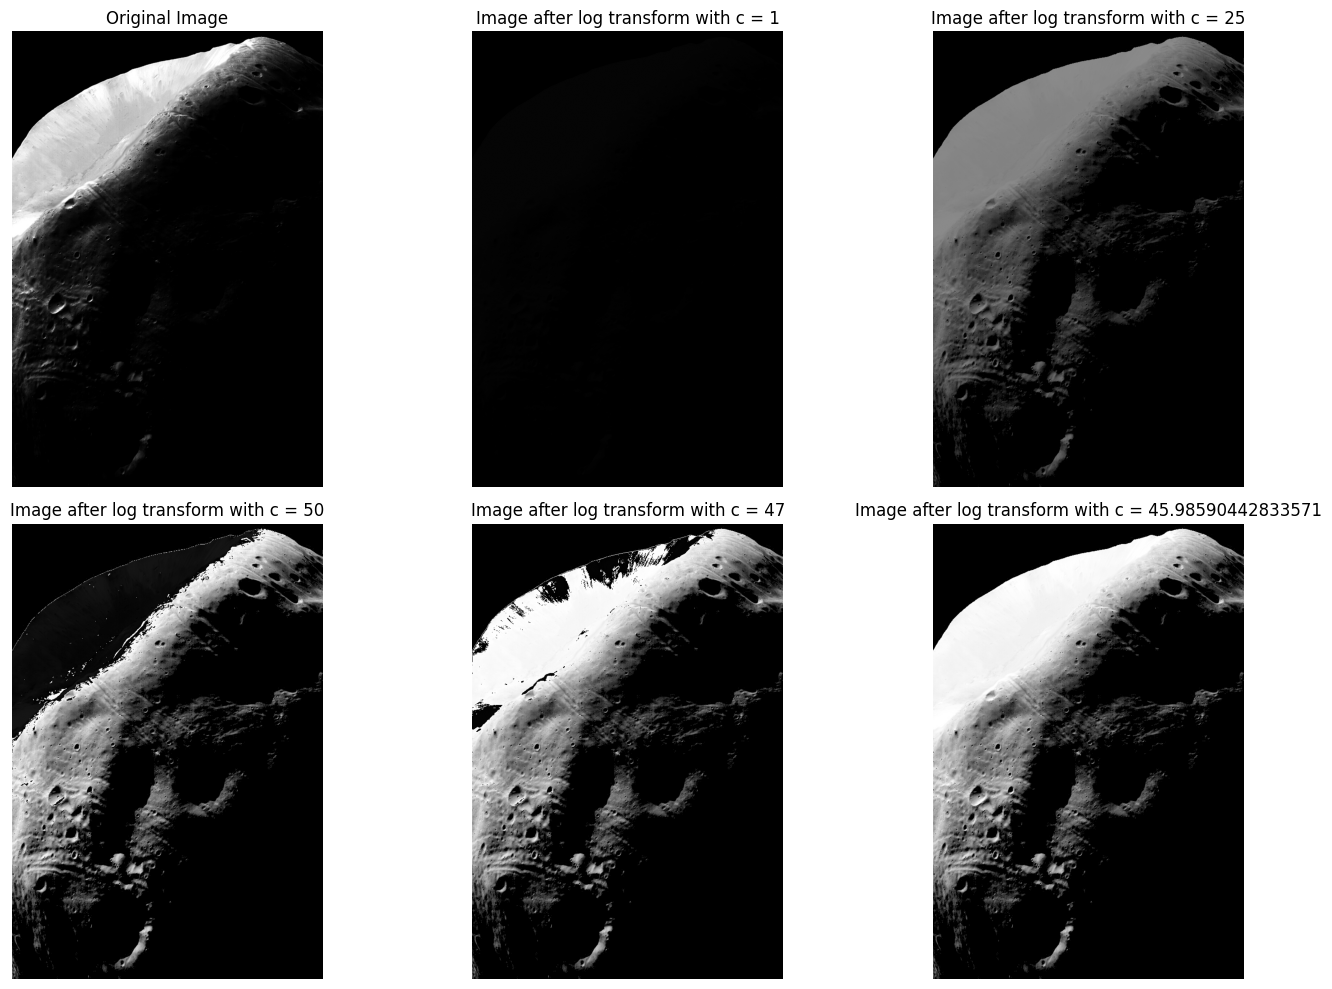

In [50]:
# read the grayscale image
img_phobos = cv2.imread(image_path / "mars_moon_phobos_dark.tif", cv2.IMREAD_GRAYSCALE)

# convert uint8 to float64
img_phobos_float = img_phobos.astype(np.float64)
log_transformed_images = []
c_values = [1, 25, 50, 47]
for c in c_values:
    log_transformed_image = (c * np.log(1 + img_phobos_float)).astype(np.uint8) # convert the processed image back to uint8 for displaying
    log_transformed_images.append(log_transformed_image)

c_optimum = 255 / np.log(1 + np.max(img_phobos_float))
c_values.append(c_optimum)
log_transformed_image_optimum = (c_optimum * np.log(1 + img_phobos_float)).astype(np.uint8)
log_transformed_images.append(log_transformed_image_optimum)

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.title("Original Image")
plt.imshow(img_phobos, cmap="gray", vmin=0, vmax=255)
plt.axis("off")

for i in range(5):
    img_pos = i + 2
    plt.subplot(2, 3, img_pos)
    plt.title(f"Image after log transform with c = {c_values[i]}")
    plt.imshow(log_transformed_images[i], cmap="gray", vmin=0, vmax=255)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Read the **fractured_spine_dark.tif** image and perform gamma correction on it using various values of `gamma` to expand the intensity levels and reduce the darkness

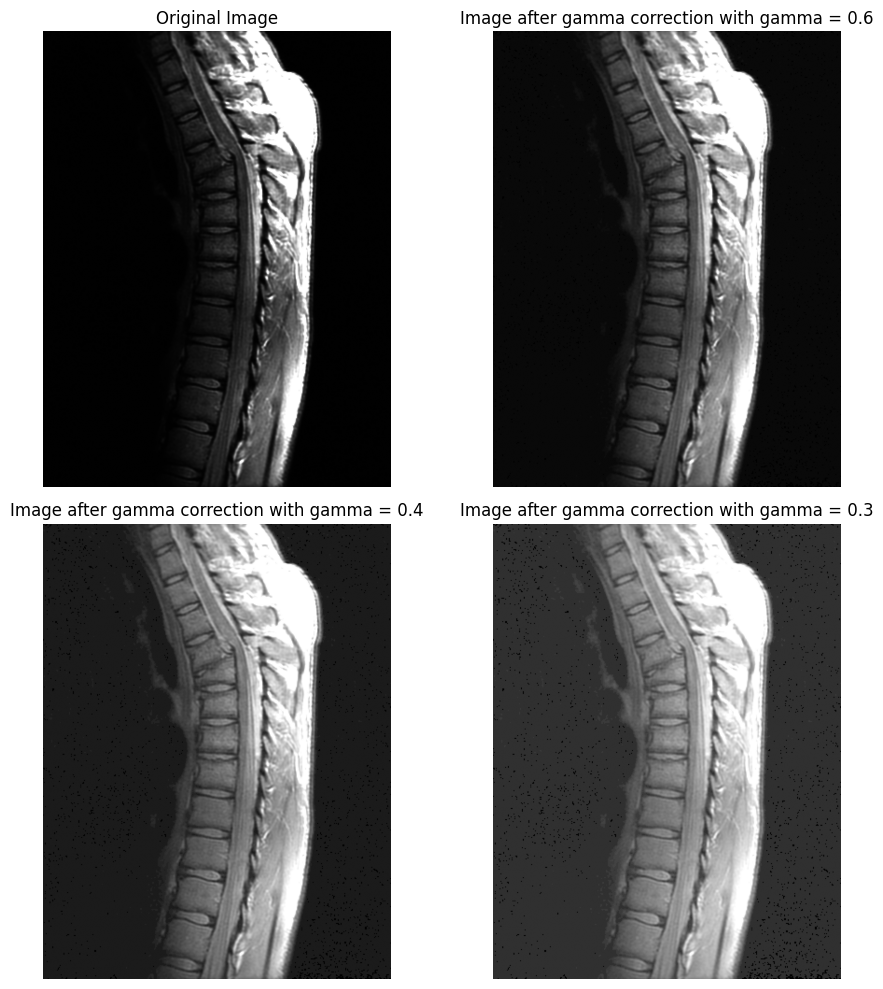

In [51]:
img_fract_spine = cv2.imread(image_path / "fractured_spine_dark.tif", cv2.IMREAD_GRAYSCALE)

img_fract_spine_float = img_fract_spine.astype(np.float64)
img_fract_spine_float_normalized = img_fract_spine_float / 255

gamma_values = [0.6, 0.4, 0.3]
gamma_corrected_images = []

for gamma in gamma_values:
    img_gamma_corrected = np.power(img_fract_spine_float_normalized, gamma)
    img_gamma_corrected_rescaled = (255 * img_gamma_corrected).astype(np.uint8)
    gamma_corrected_images.append(img_gamma_corrected_rescaled)

plt.figure(figsize=(10, 10))

plt.subplot(2, 2, 1)
plt.title("Original Image")
plt.imshow(img_fract_spine, cmap="gray", vmin=0, vmax=255)
plt.axis("off")

for i in range(3):
    img_pos = i + 2
    plt.subplot(2, 2, img_pos)
    plt.title(f"Image after gamma correction with gamma = {gamma_values[i]}")
    plt.imshow(gamma_corrected_images[i], cmap="gray", vmin=0, vmax=255)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Read the **aerial_view_washed_out.tif** image and perform gamma correction on it using various values of `gamma` to compress the intensity levels and improve the darkness

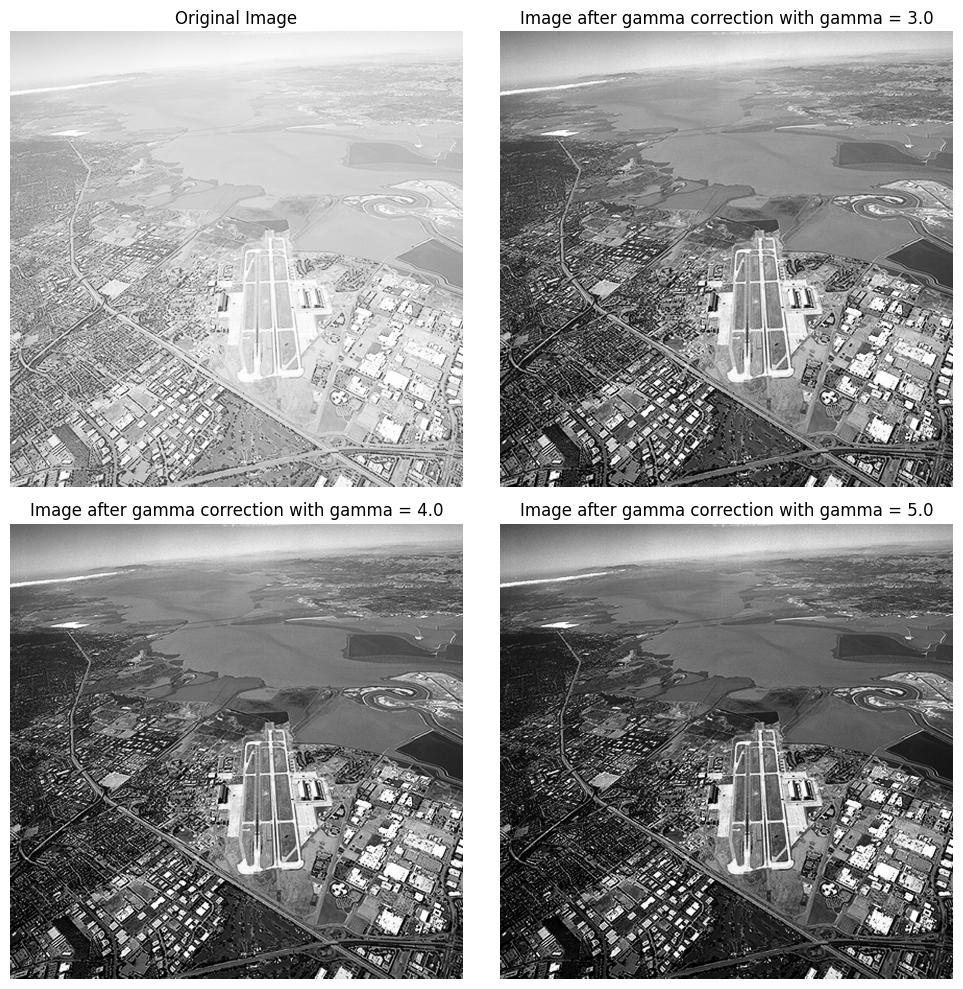

In [52]:
img_aerial_view = cv2.imread(image_path / "aerial_view_washed_out.tif", cv2.IMREAD_GRAYSCALE)

img_aerial_view_float = img_aerial_view.astype(np.float64)
img_aerial_view_float_normalized = img_aerial_view_float / 255

gamma_values = [3.0, 4.0, 5.0]
gamma_corrected_images = []

for gamma in gamma_values:
    img_gamma_corrected = np.power(img_aerial_view_float_normalized, gamma)
    img_gamma_corrected_rescaled = (255 * img_gamma_corrected).astype(np.uint8)
    gamma_corrected_images.append(img_gamma_corrected_rescaled)

plt.figure(figsize=(10, 10))

plt.subplot(2, 2, 1)
plt.title("Original Image")
plt.imshow(img_aerial_view, cmap="gray", vmin=0, vmax=255)
plt.axis("off")

for i in range(3):
    img_pos = i + 2
    plt.subplot(2, 2, img_pos)
    plt.title(f"Image after gamma correction with gamma = {gamma_values[i]}")
    plt.imshow(gamma_corrected_images[i], cmap="gray", vmin=0, vmax=255)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Read the **pollen_washed_out.tif** image and perform contrast stretching operation on it to improve the contrast

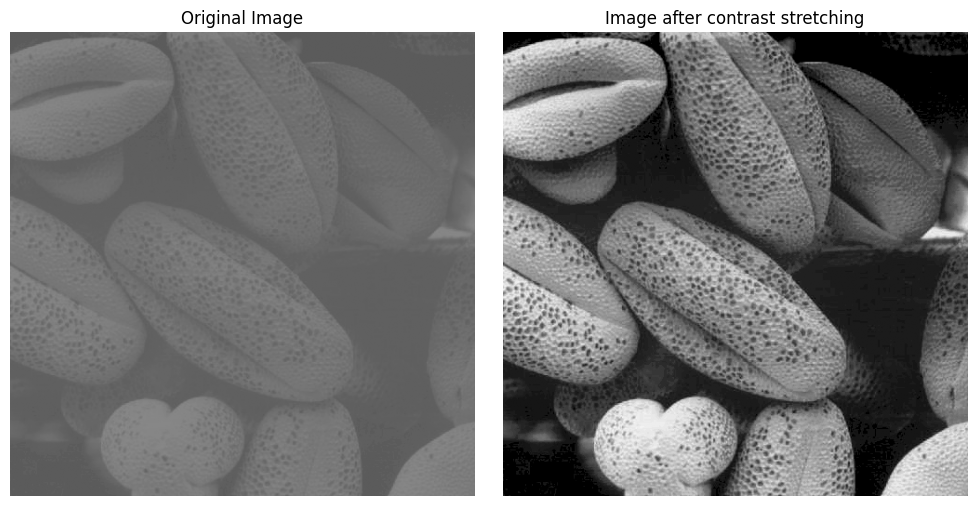

In [53]:
img_pollen_washed_out = cv2.imread(image_path / "pollen_washed_out.tif", cv2.IMREAD_GRAYSCALE)

r_min, r_max = np.min(img_pollen_washed_out), np.max(img_pollen_washed_out)
contrast_stretched = ((img_pollen_washed_out - r_min) / (r_max - r_min)) * 255
img_pollen_contrast_stretched = np.uint8(np.clip(contrast_stretched, 0, 255))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(img_pollen_washed_out, cmap="gray", vmin=0, vmax=255)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Image after contrast stretching")
plt.imshow(img_pollen_contrast_stretched, cmap="gray", vmin=0, vmax=255)
plt.axis("off")

plt.tight_layout()
plt.show()

### Read the **circuit_board_salt_pepper_noise.tif** image and smoothen it out using Gaussian and Median filters with varying sizes of the kernels.Compare the effectiveness of the two filters in noise reduction and image detail preservation.

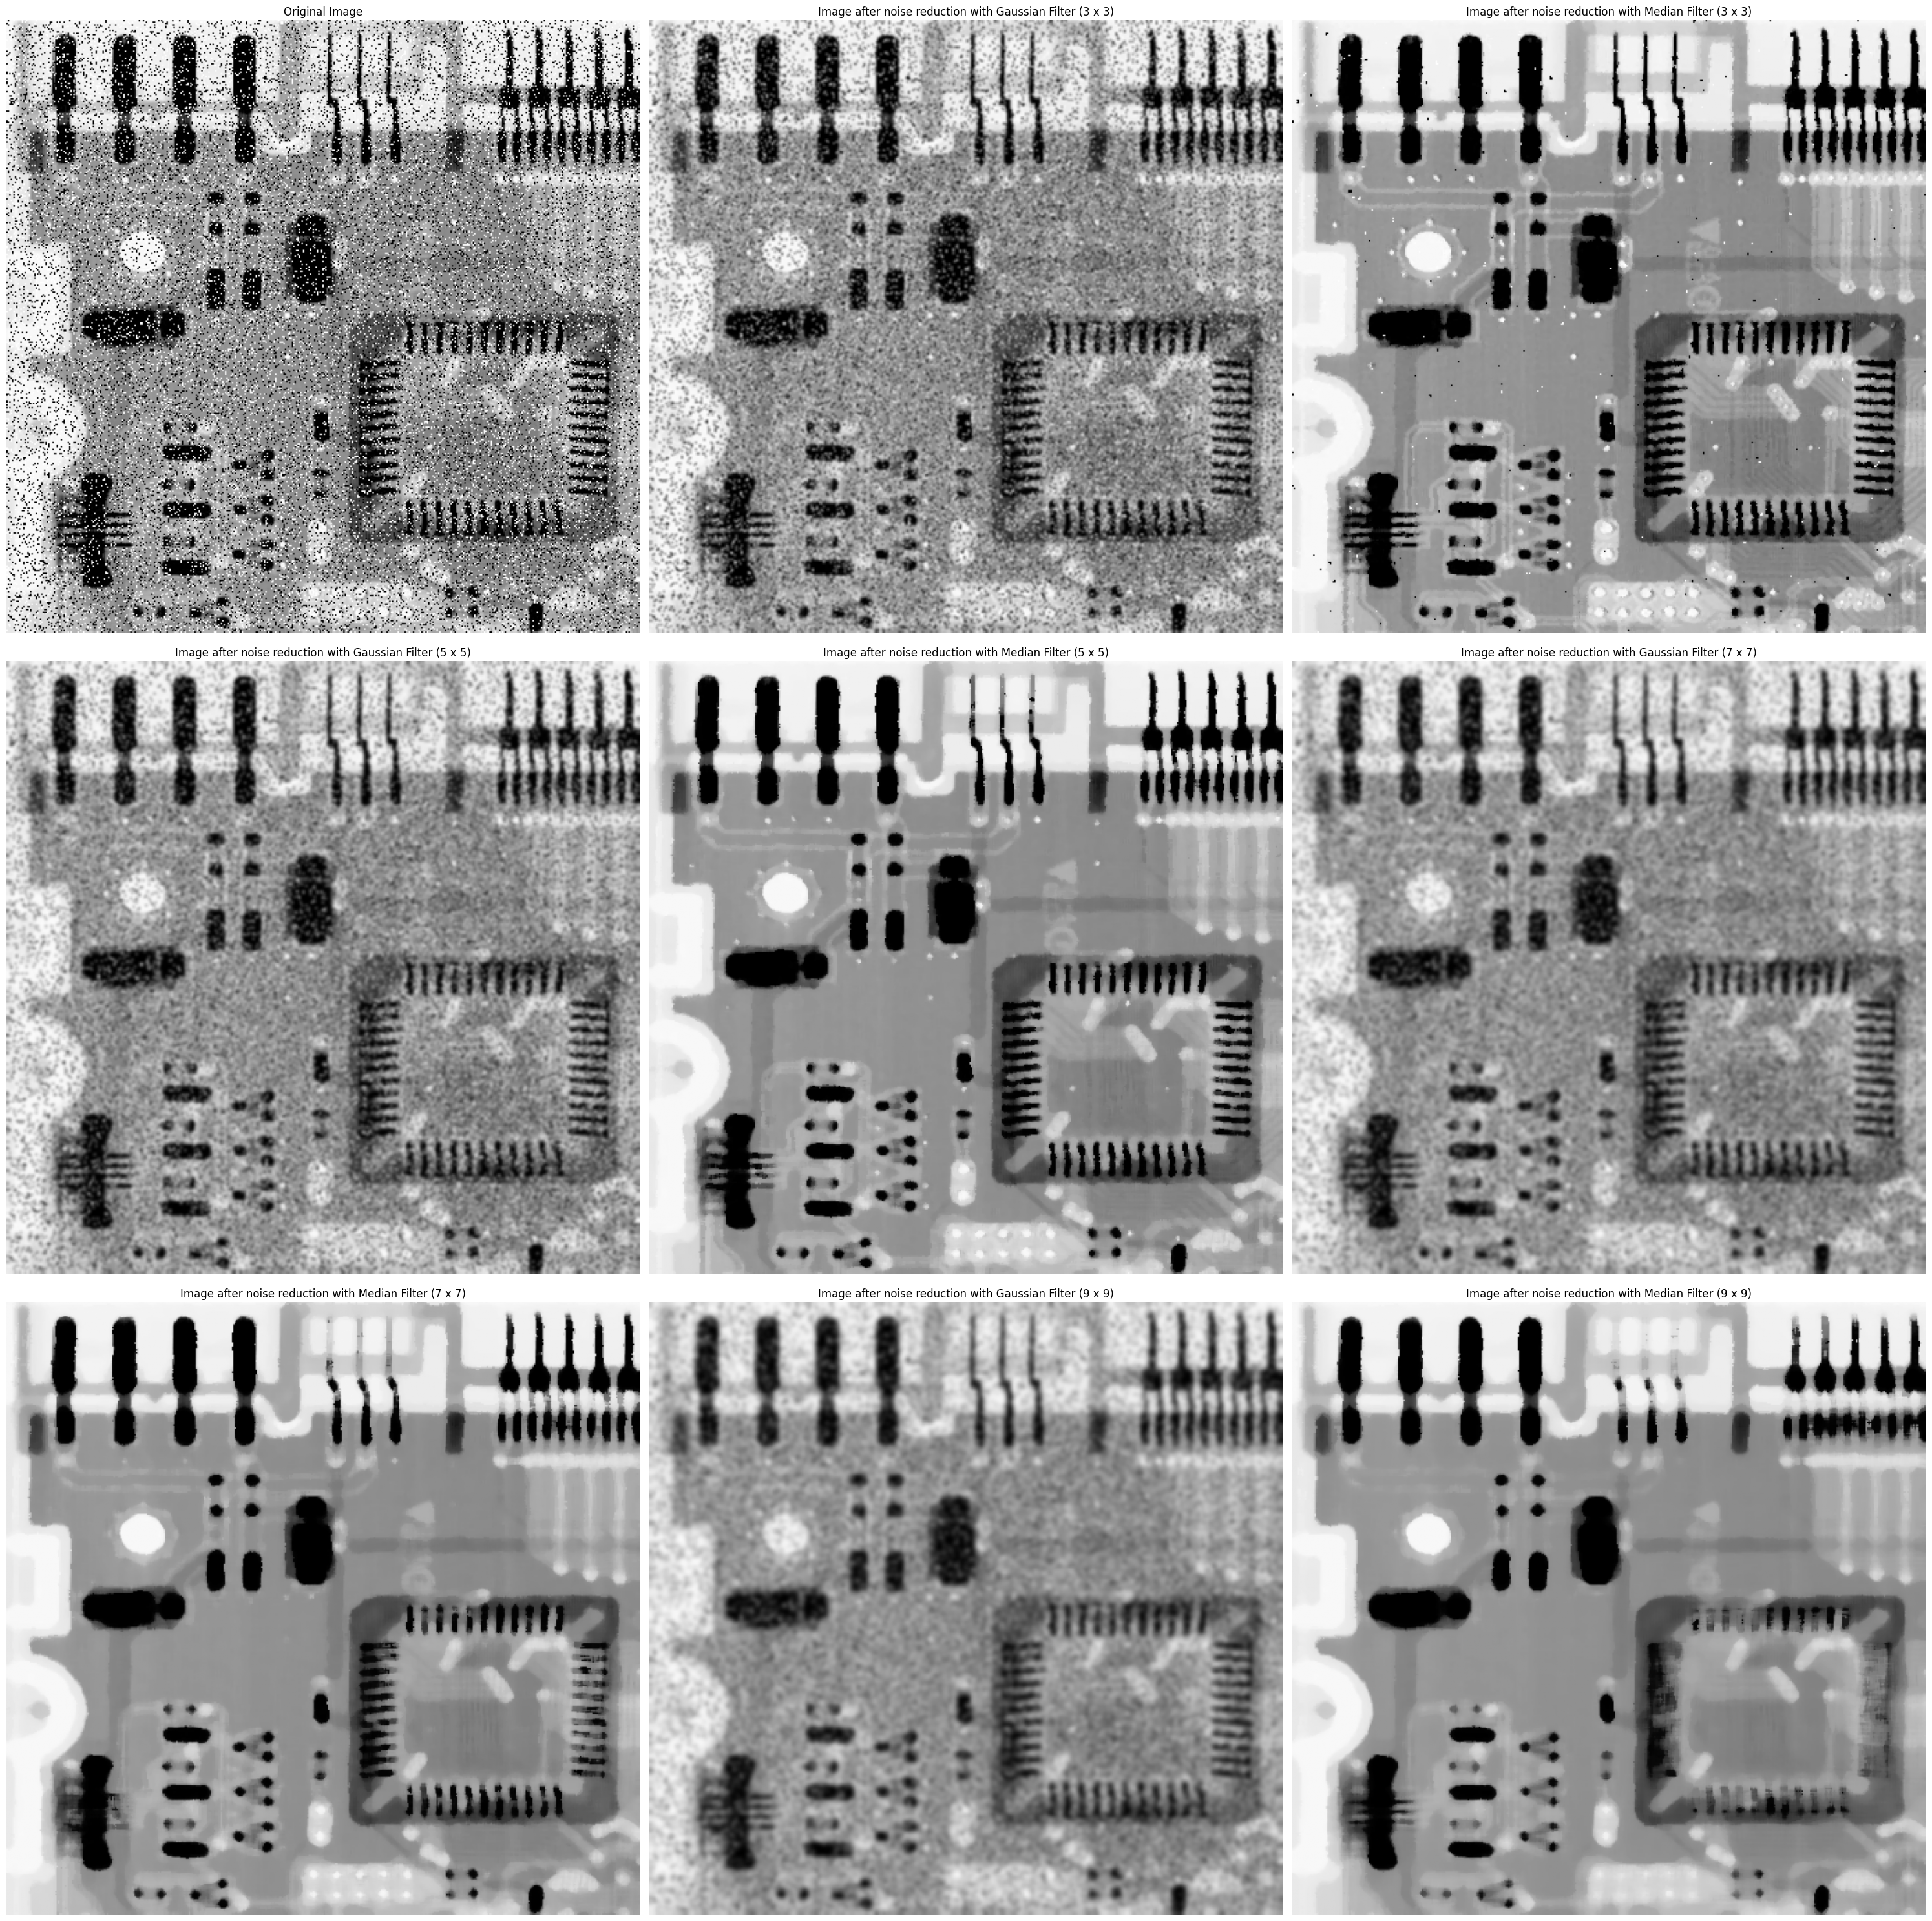

In [56]:
img_ckt_brd_spnoise = cv2.imread(image_path / "circuit_board_salt_pepper_noise.tif", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(30, 30))

plt.subplot(3, 3, 1)
plt.title("Original Image")
plt.imshow(img_ckt_brd_spnoise, cmap="gray", vmin=0, vmax=255)
plt.axis("off")

img_pos = 2
for i in range(3, 10, 2):
    img_ckt_brd_gaussian_filtered = cv2.GaussianBlur(img_ckt_brd_spnoise, (i, i), 0)
    plt.subplot(3, 3, img_pos)
    plt.title(f"Image after noise reduction with Gaussian Filter ({i} x {i})")
    plt.imshow(img_ckt_brd_gaussian_filtered, cmap="gray", vmin=0, vmax=255)
    plt.axis("off")
    img_pos += 1

    img_ckt_brd_median_filtered = cv2.medianBlur(img_ckt_brd_spnoise, i)
    plt.subplot(3, 3, img_pos)
    plt.title(f"Image after noise reduction with Median Filter ({i} x {i})")
    plt.imshow(img_ckt_brd_median_filtered, cmap="gray", vmin=0, vmax=255)
    plt.axis("off")
    img_pos += 1

plt.tight_layout()
plt.show()